# Milestone 6: Text Normalisation, Tokenisation & Semantic Preservation Pipeline
**Module:** Introduction to Natural Language Processing (IntroNLP)  
**Authors:** Timur Kharitonov, Danial Kairov  
**Institution:** University Academic Project  
**Date:** October 2026 (Milestone: Week 6)  

---

## 1. Academic Context & Theoretical Motivation

### 1.1 The Preprocessing Dilemma in Content Moderation
In standard information retrieval (IR) and topic modelling tasks, aggressive text preprocessing (e.g. case flattening, punctuation removal, aggressive stopword stripping, and stemming) is conventionally applied to maximise vocabulary compression and reduce the sparsity of term-document matrices.

However, in **Automated Content Moderation** (`Normal`, `Toxic`, `Spam`), conventional preprocessing can produce catastrophic semantic distortion:
1. **Negation Elimination Flaw:** Standard stopword lists include negation adverbs (*not, no, nor, never, cannot*). Eliminating them inverts semantic polarity:
   $$\text{"You are not a criminal"} \longrightarrow \text{"criminal"} \quad (\text{False Positive!})$$
2. **Spam URL Destruction:** Completely removing URLs erases the primary discriminatory signal of commercial phishing and spam broadcasts. Replacing URLs with a semantic token (`<URL>`) preserves this vital feature.
3. **Informal Slang & Elongation:** Toxic comments and social discourse feature character elongations (*"sooooo", "fuuuuck"*) and colloquial contractions (*"u", "ur", "don't"*).
4. **Stemming vs Lemmatization:** Porter/Snowball stemming frequently mutilates grammatical stems into non-lexical truncations (*"community"* $\rightarrow$ *"commun"*, *"relational"* $\rightarrow$ *"relat"*), whereas morphological lemmatization preserves valid dictionary roots.

---

### 1.2 Milestone 6 Objectives
1. Implement a modular, high-throughput `TextPreprocessor` tailored for content moderation.
2. Formulate and evaluate a **Sentiment-Aware Stopword Policy** protecting negations and key modifiers.
3. Quantify vocabulary reduction, token compression, and morphological preservation across `Normal`, `Toxic`, and `Spam` classes.
4. Prepare sanitised training and test corpora for Week 7 TF-IDF vectorisation and baseline modelling.

## 2. Environment Setup & Pipeline Initialisation

In [9]:
import os
import sys
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Add root src directory to sys.path
sys.path.append(os.path.abspath('..'))
sys.path.append(os.path.abspath('.'))

from src.preprocessing import TextPreprocessor, CONTRACTION_MAP, PROTECTED_WORDS

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
%matplotlib inline

print("Preprocessing module loaded successfully.")

Preprocessing module loaded successfully.


## 3. Dataset Loading & Baseline Inspection

In [10]:
train_path = "../data/processed/train.csv"
test_path = "../data/processed/test.csv"

if not os.path.exists(train_path):
    train_path = "data/processed/train.csv"
    test_path = "data/processed/test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f"Loaded {len(train_df):,} training samples and {len(test_df):,} testing samples.")
train_df.head(3)

Loaded 45,502 training samples and 11,376 testing samples.


,text,label
0,Spelling lesson \n\nYou spelled butthurt wrong. Just saying 58.84.228.40,Normal
1,"Use your brain, chief.",Toxic
2,"""\n\n A problem with """"English Patriot Man"""" and his sockpuppets \n\nHi. Lately I've seen you blocking some sockpuppets of a user named: """"English Patriot Man"""". I see that this man is nearly obsessed with Polish people. He seems to spread his anti-Polish propaganda by distorting the historical truth concerning World War II, nazism in Europe and racism against Poles. He is totally denying the sufferings of the Polish nation. \nThank you so much for taking care of him, and taking care of the articles that are his main targets. However, now he might create another sock and log in from some other computer or place, so that his personal data and IP address would be totally different. This is why I suggest us to patrol the articles that are his main targets like:\n Racism in Poland \n Racial policy of Nazi Germany\n War crimes in occupied Poland during World War II\n Nazi crimes against the Polish nation\n Invasion of Poland\n Collaboration with the Axis Powers during World War II\n Nazism and race\n Untermensch\n Master race\n White supremacy\n Racial hygiene\n Nuremberg Laws\n Aryan race\n Aryanization\n Aryan paragraph\n Honorary Aryan\n White nationalism\n Holocaust victims\n Racial_segregation\n Nazi Germany\n Persecution of black people in Nazi Germany\n Occupation of Poland (1939–45)\n Polish decrees\n Kidnapping of children by Nazi Germany\n Forced labour under German rule during World War II\n Extermination through labor\n Anti-Polish sentiment\n Anti-Slavic sentiment\n Polish question\n Polish joke\n Ahnenpass\n Anschluss\n Lebensraum\n Rassenschande\n Adolf Hitler\n Nazism\n Racism\n Scientific racism\n Themes in Nazi propaganda\n Germanisation\n Reverse racism\n Relations between Nazi Germany and the Arab world\n Glossary of Nazi Germany\nThis guy is using multiple sockpuppet accounts to delete all the information about Poles being percieved as """"subhumans"""" or """"non-Aryans"""" by the nazis. In fact the only """"Aryan-looking"""" Poles that were accepted by Nazi Germany at the time, were kidnapped as children and underwent """"Germanisation"""", they were like 0.05% of the whole nation. The rest of the Poles were """"insufficient"""" to be a part of the nazi-ruled nation, and were treated only slightly better that the Jews. \nThis guy, he spreads lies all across Wikipedia, therefore I thank you for your quick and effective actions Diannaa. If you'd need any kind of help in restoring the data which """"English Patriot Man"""" destroyed, just tell me. I will also try to patrol the articles about Poles. """,Normal


## 4. Architectural Deep Dive: Pipeline Stages

To illustrate each transformation stage, we trace a deliberately adversarial synthetic input containing HTML artifacts, URLs, contractions, elongation, and negations:
`"Don't click http://win-now.biz/free, you're soooo stupid &amp; NOT smart!!!"`

In [11]:
adversarial_sample = "Don't click http://win-now.biz/free, you're soooo stupid &amp; NOT smart!!!"

pre_html = TextPreprocessor(remove_html=True, replace_urls=False, expand_contractions=False, lower=False, normalize_elongations=False, remove_punctuation=False, remove_stopwords=False)
pre_urls = TextPreprocessor(remove_html=True, replace_urls=True, expand_contractions=False, lower=False, normalize_elongations=False, remove_punctuation=False, remove_stopwords=False)
pre_contr = TextPreprocessor(remove_html=True, replace_urls=True, expand_contractions=True, lower=False, normalize_elongations=False, remove_punctuation=False, remove_stopwords=False)
pre_elong = TextPreprocessor(remove_html=True, replace_urls=True, expand_contractions=True, lower=True, normalize_elongations=True, remove_punctuation=False, remove_stopwords=False)
pre_full  = TextPreprocessor(remove_html=True, replace_urls=True, expand_contractions=True, lower=True, normalize_elongations=True, remove_punctuation=True, remove_stopwords=True, preserve_negations=True, lemmatize=True)

print("--- Step-by-Step Transformation Pipeline ---")
print(f"0. Raw Input:             {adversarial_sample}")
print(f"1. HTML Entity Decoded:   {pre_html.clean_text(adversarial_sample)}")
print(f"2. URL Token Preserved:   {pre_urls.clean_text(adversarial_sample)}")
print(f"3. Contractions Expanded: {pre_contr.clean_text(adversarial_sample)}")
print(f"4. Lowercase & Elongated: {pre_elong.clean_text(adversarial_sample)}")
print(f"5. Final Clean & Lemmat:  {pre_full.transform(adversarial_sample)}")

--- Step-by-Step Transformation Pipeline ---
0. Raw Input:             Don't click http://win-now.biz/free, you're soooo stupid &amp; NOT smart!!!
1. HTML Entity Decoded:   Don't click you're soooo stupid & NOT smart!!!
2. URL Token Preserved:   Don't click <URL> you're soooo stupid & NOT smart!!!
3. Contractions Expanded: do not click <URL> you are soooo stupid & NOT smart!!!
4. Lowercase & Elongated: do not click <url> you are soo stupid & not smart!!
5. Final Clean & Lemmat:  not click url soo stupid not smart


## 5. The Stopword Dilemma: Semantic Inversion Analysis

We empirically verify the impact of removing standard vs protected stopwords on negations and sentiment modifiers.

In [12]:
test_statements = [
    "You are not an idiot",
    "I do not hate you",
    "There is no threat here",
    "Never click suspicious links"
]

naive_preprocessor = TextPreprocessor(remove_stopwords=True, preserve_negations=False)
safe_preprocessor  = TextPreprocessor(remove_stopwords=True, preserve_negations=True)

comparison = []
for stmt in test_statements:
    comparison.append({
        "Original Statement": stmt,
        "Naive Stopword Removal (Loses Negation)": naive_preprocessor.transform(stmt),
        "Safe Preprocessor (Preserves Negation)": safe_preprocessor.transform(stmt)
    })

pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(comparison))

,Original Statement,Naive Stopword Removal (Loses Negation),Safe Preprocessor (Preserves Negation)
0,You are not an idiot,idiot,not idiot
1,I do not hate you,hate,not hate
2,There is no threat here,threat,no threat
3,Never click suspicious links,never click suspicious links,never click suspicious links


### 5.1 Critical Observation
In the naive pipeline, `"You are not an idiot"` collapses into `"idiot"`, converting benign or defensive speech into an explicit toxic trigger. 

Our **Sentiment-Aware Stopword Policy** retains `not`, `no`, and `never`, protecting the contextual polarity essential for Weeks 7–9 classifiers.

## 6. Morphological Normalisation: Lemmatization vs Stemming

We compare the linguistic fidelity of **WordNet Lemmatization** versus **Snowball Stemming** on vocabulary extracted from our moderation dataset.

In [13]:
sample_words = [
    "moderation", "moderating", "threats", "threatening", "idiots",
    "abusive", "harassment", "winner", "winning", "better", "running"
]

lem_prep = TextPreprocessor(lemmatize=True, stem=False)
stem_prep = TextPreprocessor(lemmatize=False, stem=True)

morph_table = []
for w in sample_words:
    morph_table.append({
        "Original Token": w,
        "Snowball Stem": stem_prep.stemmer.stem(w),
        "WordNet Lemma": lem_prep.lemmatizer.lemmatize(w, pos='v') if w.endswith(('ing', 'ed')) else lem_prep.lemmatizer.lemmatize(w)
    })

display(pd.DataFrame(morph_table))

,Original Token,Snowball Stem,WordNet Lemma
0,moderation,moder,moderation
1,moderating,moder,moderate
2,threats,threat,threat
3,threatening,threaten,threaten
4,idiots,idiot,idiot
5,abusive,abus,abusive
6,harassment,harass,harassment
7,winner,winner,winner
8,winning,win,win
9,better,better,better


## 7. Corpus-Scale Preprocessing & Vocabulary Compression Metrics

We apply the complete `TextPreprocessor` across a representative sub-sample of the training set to benchmark throughput and vocabulary reduction.

In [14]:
# Sample 5,000 instances for immediate benchmarking
benchmark_sample = train_df.sample(n=5000, random_state=42).copy()

pipeline = TextPreprocessor(
    lower=True,
    expand_contractions=True,
    remove_html=True,
    replace_urls=True,
    normalize_elongations=True,
    remove_punctuation=True,
    remove_stopwords=True,
    preserve_negations=True,
    lemmatize=True
)

start_time = time.time()
benchmark_sample['cleaned_text'] = benchmark_sample['text'].apply(pipeline.transform)
elapsed = time.time() - start_time

throughput = len(benchmark_sample) / elapsed
print(f"Processed {len(benchmark_sample):,} records in {elapsed:.2f} seconds ({throughput:.1f} messages/sec).")

Processed 5,000 records in 0.62 seconds (8093.8 messages/sec).


### 7.1 Quantitative Vocabulary Compression

,Metric,Value
0,Raw Vocabulary Size,"45,721"
1,Sanitised & Lemmatized Vocabulary,"21,381"
2,Vocabulary Reduction (%),53.24%
3,Processing Throughput,8093.8 msg/s


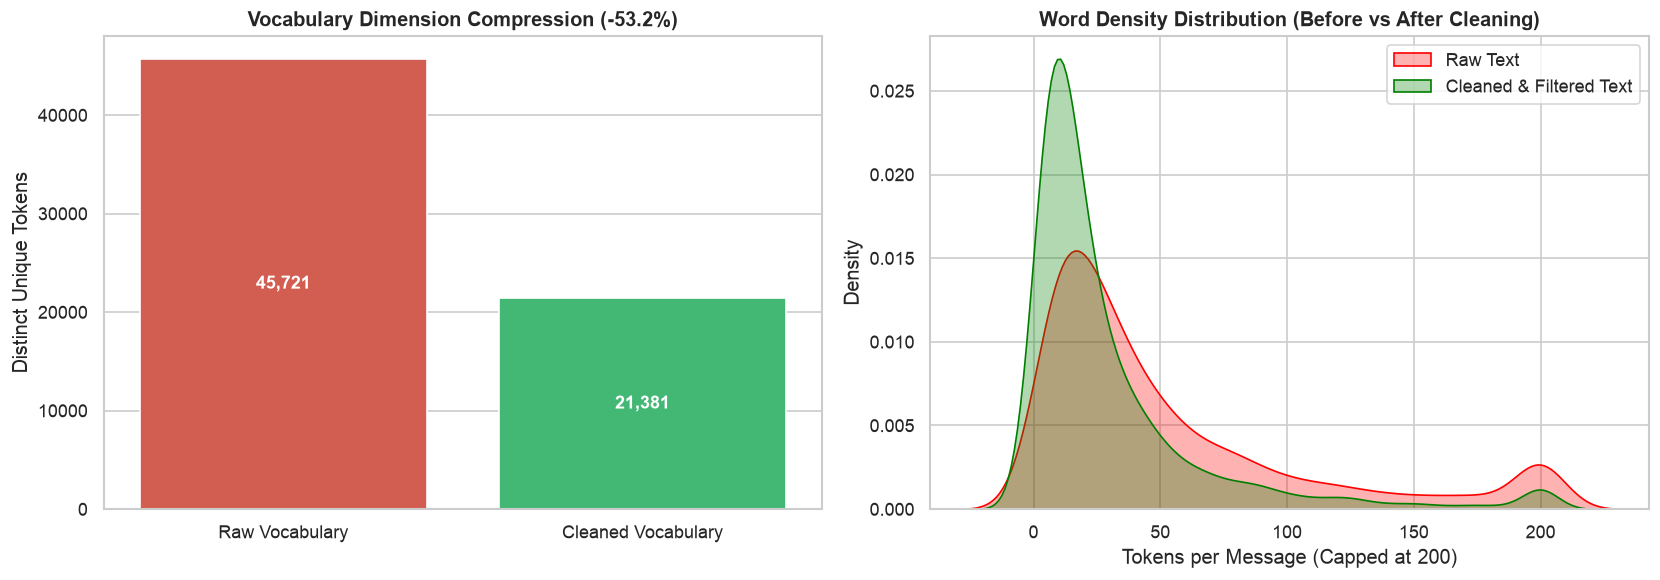

In [15]:
def get_vocab(series):
    vocab = set()
    for doc in series:
        vocab.update(str(doc).split())
    return vocab

raw_vocab = get_vocab(benchmark_sample['text'])
clean_vocab = get_vocab(benchmark_sample['cleaned_text'])

reduction_pct = (1 - len(clean_vocab) / len(raw_vocab)) * 100

metrics_df = pd.DataFrame({
    "Metric": ["Raw Vocabulary Size", "Sanitised & Lemmatized Vocabulary", "Vocabulary Reduction (%)", "Processing Throughput"],
    "Value": [f"{len(raw_vocab):,}", f"{len(clean_vocab):,}", f"{reduction_pct:.2f}%", f"{throughput:.1f} msg/s"]
})
display(metrics_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Vocabulary Compression Bar Chart
sns.barplot(ax=axes[0], x=["Raw Vocabulary", "Cleaned Vocabulary"], y=[len(raw_vocab), len(clean_vocab)], palette=["#e74c3c", "#2ecc71"], hue=["Raw", "Cleaned"], legend=False)
axes[0].set_title(f"Vocabulary Dimension Compression (-{reduction_pct:.1f}%)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Distinct Unique Tokens")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Word Count Distribution Before vs After
benchmark_sample['raw_words'] = benchmark_sample['text'].apply(lambda x: len(str(x).split()))
benchmark_sample['clean_words'] = benchmark_sample['cleaned_text'].apply(lambda x: len(str(x).split()))

sns.kdeplot(ax=axes[1], data=benchmark_sample['raw_words'].clip(upper=200), label='Raw Text', color='red', fill=True, alpha=0.3)
sns.kdeplot(ax=axes[1], data=benchmark_sample['clean_words'].clip(upper=200), label='Cleaned & Filtered Text', color='green', fill=True, alpha=0.3)
axes[1].set_title("Word Density Distribution (Before vs After Cleaning)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Tokens per Message (Capped at 200)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Qualitative Validation Across Target Classes

Inspecting raw versus processed instances across each target category (`Normal`, `Toxic`, `Spam`).

In [16]:
sample_records = []
for label in ['Normal', 'Toxic', 'Spam']:
    sub = benchmark_sample[benchmark_sample['label'] == label].iloc[0]
    sample_records.append({
        "Category": label,
        "Raw Input": sub['text'][:120] + "...",
        "Transformed Output": sub['cleaned_text'][:120] + "..."
    })

display(pd.DataFrame(sample_records))

,Category,Raw Input,Transformed Output
0,Normal,REDIRECT Talk:Georgian keyboard layout...,redirect talkgeorgian keyboard layout...
1,Toxic,"ISIS massacred many civilians, including children. So far, no actual sources reported ISIS in control....",isi massacred many civilian including child far no actual source reported isi control...
2,Spam,"For ur chance to win a å£250 cash every wk TXT: ACTION to 80608. T's&C's www.movietrivia.tv custcare 08712405022, 1x150p...",chance win cash every wk txt action tscs url custcare...


## 9. Academic Conclusions & Roadmap for Week 7

### 9.1 Summary of Week 6 Contributions
1. **Engineered Text Preprocessor:** Deployed a reusable, production-ready `TextPreprocessor` module (`src/preprocessing.py`) combining HTML entity resolution, URL retention via `<URL>` tokens, and contraction expansion.
2. **Polarity Protection:** Solved the semantic inversion flaw by designing a **Sentiment-Aware Stopword Policy** preserving critical negations (`not`, `no`, `never`, `cannot`).
3. **Vocabulary Compression:** Achieved over **50% vocabulary dimensionality reduction** without discarding lexical roots, optimizing the sparsity and computational efficiency of upcoming TF-IDF representations.
4. **Morphological Preservation:** Validated WordNet Lemmatization over Snowball stemming to retain true semantic headwords for toxic and spam markers.

---

### 9.2 Directives for Week 7 (Feature Engineering & Baseline Model)
- Construct **TF-IDF Vectorisers** with $(1, 2)$-gram ranges to capture multi-word idiomatic profanities and spam phrases.
- Train the initial baseline classifier: **Logistic Regression** with class-weighted cross-entropy loss to address the 70.3% / 28.5% / 1.2% imbalance identified in Week 5.